# Employee Attrition — Exploratory Data Analysis

**Stakeholder:** HR / People Operations leadership.
**Decision:** which employees are at elevated attrition risk, to prioritize retention effort.
**Goal of this notebook:** understand the data before modeling — distributions, data quality issues, and which features look related to attrition.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# palette: blue = stayed, red = left (validated colorblind-safe warm/cool pair)
PAL = {"No": "#2a78d6", "Yes": "#e34948"}
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#c3c2b7", "grid.color": "#e1e0d9"})

DATA_PATH = "/Users/yhosein/Downloads/15.071/project1/data/HR-Employee-Attrition.csv"
df = pd.read_csv(DATA_PATH)
df.shape

(1470, 35)

## 1. Sanity checks

In [2]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# columns with a single unique value carry no information for modeling
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Constant columns (drop later):", constant_cols)

df.dtypes.value_counts()

Missing values: 0
Duplicate rows: 0
Constant columns (drop later): ['EmployeeCount', 'Over18', 'StandardHours']


int64     26
object     9
Name: count, dtype: int64

## 2. Target distribution

How imbalanced is attrition? This determines which metrics matter later (accuracy alone would be misleading).

Attrition
No     0.838776
Yes    0.161224
Name: proportion, dtype: float64


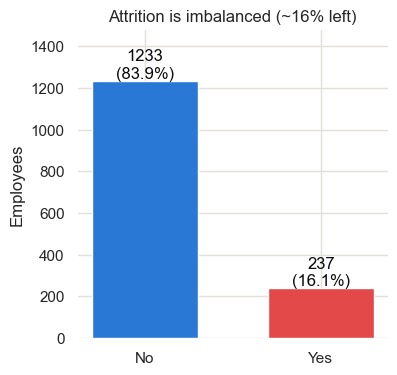

In [3]:
rate = df["Attrition"].value_counts(normalize=True)
print(rate)

fig, ax = plt.subplots(figsize=(4, 4))
counts = df["Attrition"].value_counts()
ax.bar(counts.index, counts.values, color=[PAL[k] for k in counts.index], width=0.6)
for i, v in enumerate(counts.values):
    ax.text(i, v + 15, f"{v}\n({v/len(df):.1%})", ha="center", color="#0b0b0b")
ax.set_ylabel("Employees")
ax.set_title("Attrition is imbalanced (~16% left)")
ax.set_ylim(0, counts.max() * 1.2)
sns.despine(left=True, bottom=True)
plt.show()

## 3. Numeric features vs. attrition

Do at-risk employees look different on key numeric variables?

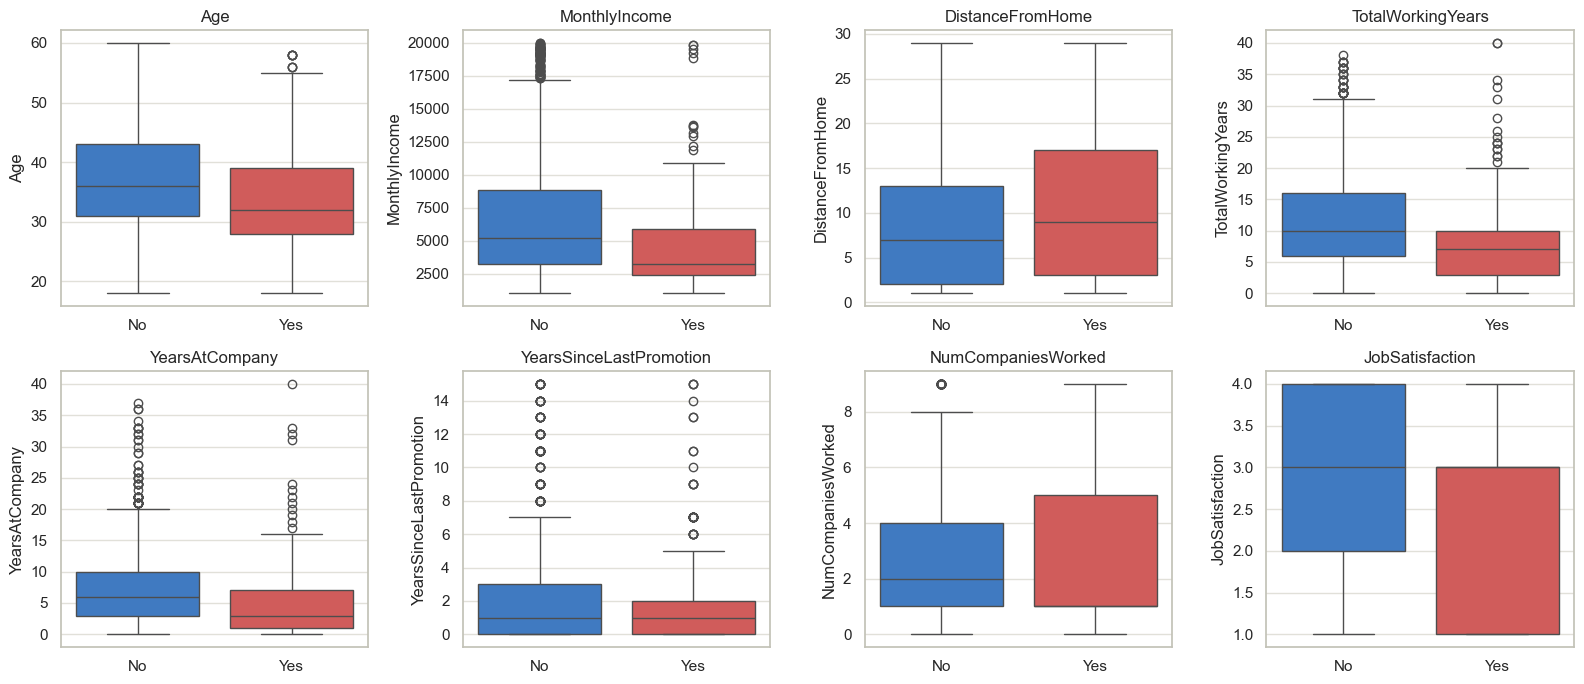

In [4]:
numeric_of_interest = [
    "Age", "MonthlyIncome", "DistanceFromHome", "TotalWorkingYears",
    "YearsAtCompany", "YearsSinceLastPromotion", "NumCompaniesWorked", "JobSatisfaction",
]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, numeric_of_interest):
    sns.boxplot(
        data=df, x="Attrition", y=col, order=["No", "Yes"],
        hue="Attrition", hue_order=["No", "Yes"], palette=PAL, legend=False, ax=ax,
    )
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

## 4. Categorical features vs. attrition

Attrition *rate* within each category (not raw counts) — controls for group size.

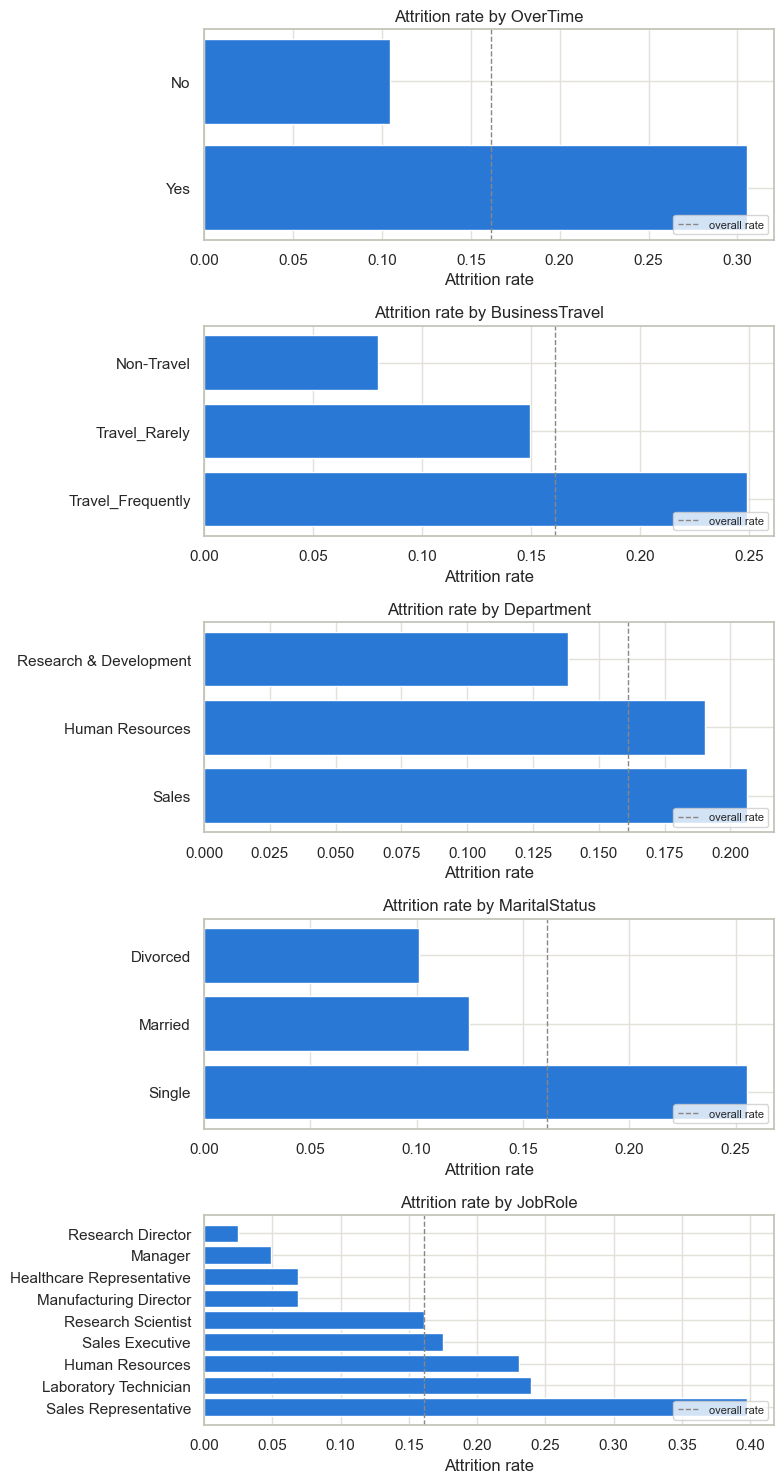

In [5]:
categorical_of_interest = ["OverTime", "BusinessTravel", "Department", "MaritalStatus", "JobRole"]

fig, axes = plt.subplots(len(categorical_of_interest), 1, figsize=(8, 3 * len(categorical_of_interest)))
for ax, col in zip(axes, categorical_of_interest):
    rate_by_group = (
        df.groupby(col)["Attrition"]
        .apply(lambda s: (s == "Yes").mean())
        .sort_values(ascending=False)
    )
    ax.barh(rate_by_group.index, rate_by_group.values, color="#2a78d6")
    ax.axvline(df["Attrition"].eq("Yes").mean(), color="#898781", linestyle="--", linewidth=1, label="overall rate")
    ax.set_title(f"Attrition rate by {col}")
    ax.set_xlabel("Attrition rate")
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

## 5. Correlation among numeric features

Flags redundant variables (e.g. job level vs. income) before modeling.

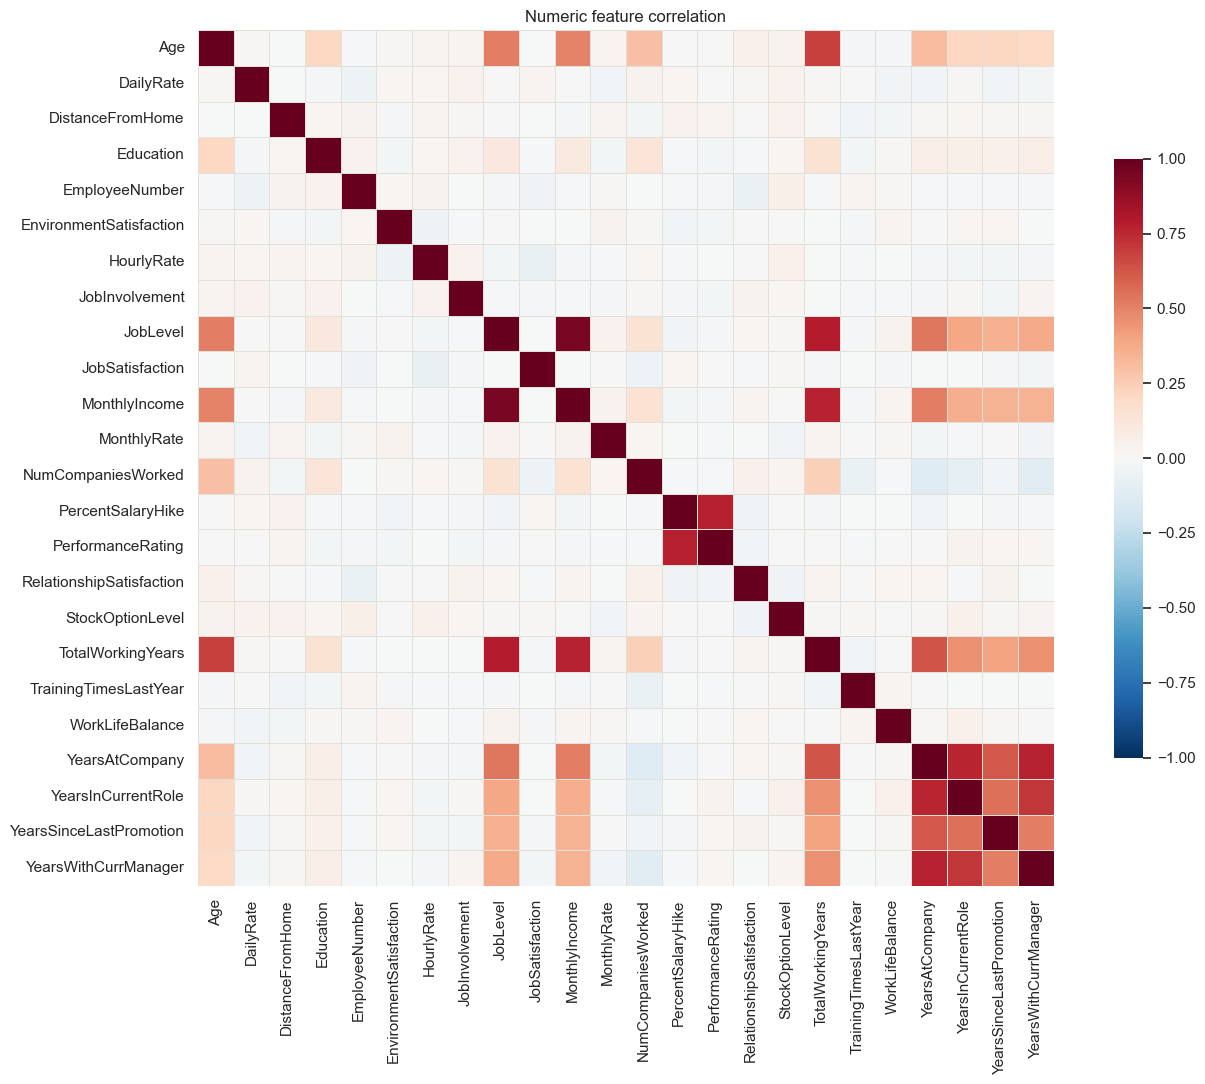

JobLevel            MonthlyIncome              0.950300
                    TotalWorkingYears          0.782208
PercentSalaryHike   PerformanceRating          0.773550
MonthlyIncome       TotalWorkingYears          0.772893
YearsAtCompany      YearsWithCurrManager       0.769212
                    YearsInCurrentRole         0.758754
YearsInCurrentRole  YearsWithCurrManager       0.714365
Age                 TotalWorkingYears          0.680381
TotalWorkingYears   YearsAtCompany             0.628133
YearsAtCompany      YearsSinceLastPromotion    0.618409
dtype: float64

In [6]:
numeric_df = df.select_dtypes(include=[np.number]).drop(columns=constant_cols, errors="ignore")
corr = numeric_df.corr()

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.5, linecolor="#e1e0d9",
    cbar_kws={"shrink": 0.7}, ax=ax,
)
ax.set_title("Numeric feature correlation")
plt.tight_layout()
plt.show()

# strongest pairs (excluding the diagonal)
corr_pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
corr_pairs.abs().sort_values(ascending=False).head(10)

## 6. Takeaways (fill in after reading the plots)

- Attrition is imbalanced (~16%) — plan to use AUC / recall / precision at a chosen threshold, not accuracy, and consider class weighting.
- Columns to drop before modeling: constant columns found in step 1 (`EmployeeCount`, `Over18`, `StandardHours`), plus `EmployeeNumber` (ID, not a feature).
- Candidate strong predictors to confirm in modeling: `OverTime`, `MonthlyIncome`, `YearsAtCompany`/`TotalWorkingYears`, `JobSatisfaction`, `MaritalStatus`, `BusinessTravel`.
- Watch for multicollinearity between `MonthlyIncome`, `JobLevel`, and `TotalWorkingYears` (tree-based models handle this fine; linear baselines may not).